In [2]:
# SECTION 1: SETUP
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
os.makedirs("images", exist_ok=True)

df = pd.read_excel("Cleaned_Dataset.xlsx")
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df.Date.dt.year
df["Month"] = df.Date.dt.month

# Design system from the slides: grey for context, ONE accent color for the insight
GREY, DARK, ACCENT = "#B8BFCC", "#2B3445", "#0B6EC3"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,   # remove chartjunk
    "axes.edgecolor": GREY, "xtick.color": DARK, "ytick.color": DARK,
})

In [3]:
# SECTION 2: HELPER FUNCTION (action title + subtitle + source footnote)
def finish(fig, title, subtitle, name,
           source="Source: Cleaned_Dataset.xlsx, 1,200 orders (Jan 2023 - Jun 2025)"):
    """Adds action title, subtitle and source, then saves the chart to images/"""
    fig.suptitle(title, x=0.01, y=0.99, ha="left", va="top",
                 fontsize=17, fontweight="bold", color=DARK)       # action title
    fig.text(0.01, 0.89, subtitle, fontsize=11, color="#5B6577")   # context line
    fig.text(0.01, 0.01, source, fontsize=8, color="#8A93A3")      # footnote
    fig.subplots_adjust(top=0.80, bottom=0.12, left=0.08, right=0.97)
    fig.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [4]:
# SECTION 3: KEY NUMBERS (used in titles, so nothing is hard-coded)
total_rev = df.TotalPrice.sum()
n_orders = len(df)
aov = df.TotalPrice.mean()
failed = df.OrderStatus.isin(["Cancelled", "Returned"])
fail_pct = failed.mean() * 100

print(f"{total_rev} \n {n_orders} \n {aov} \n {fail_pct}")

1264761.96 
 1200 
 1053.9683 
 41.41666666666667


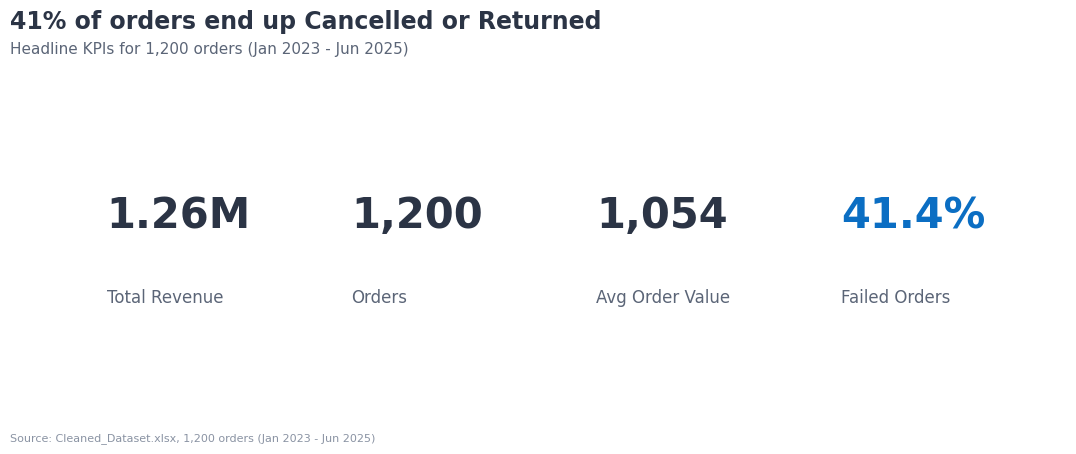

In [5]:
# SECTION 4: CHART 1 - KPI SUMMARY (5-second rule: key metrics first)
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.axis("off")
kpis = [("Total Revenue", f"{total_rev/1e6:.2f}M", False),
        ("Orders", f"{n_orders:,}", False),
        ("Avg Order Value", f"{aov:,.0f}", False),
        ("Failed Orders", f"{fail_pct:.1f}%", True)]     # True = highlight in accent
for i, (label, value, hl) in enumerate(kpis):
    x = i / 4 + 0.02
    ax.text(x, 0.55, value, fontsize=30, fontweight="bold",
            color=ACCENT if hl else DARK, transform=ax.transAxes)
    ax.text(x, 0.30, label, fontsize=12, color="#5B6577", transform=ax.transAxes)
finish(fig, f"{fail_pct:.0f}% of orders end up Cancelled or Returned",
       "Headline KPIs for 1,200 orders (Jan 2023 - Jun 2025)", "01_kpi_summary")

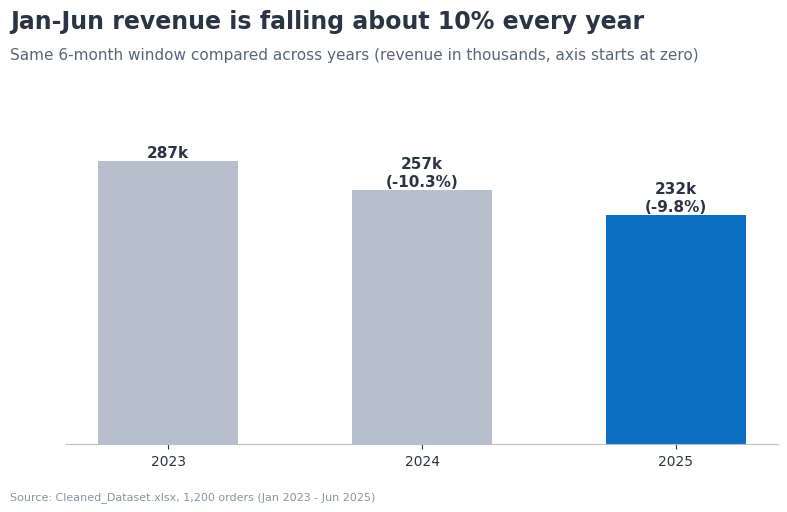

In [6]:
# SECTION 5: CHART 2 - TREND (fair H1 comparison, highlight latest year)
h1 = df[df.Month <= 6].groupby("Year").TotalPrice.sum()   # same 6 months each year
chg = h1.pct_change() * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(h1.index.astype(str), h1.values/1e3, color=[GREY, GREY, ACCENT], width=0.55)
for bar, yr in zip(bars, h1.index):
    label = f"{bar.get_height():.0f}k"
    if not np.isnan(chg[yr]):
        label += f"\n({chg[yr]:+.1f}%)"                    # direct label with change
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 4, label,
            ha="center", fontsize=11, fontweight="bold", color=DARK)
ax.set_ylim(0, h1.max()/1e3 * 1.2)                          # axis starts at zero
ax.set_yticks([]); ax.spines["left"].set_visible(False)
finish(fig, "Jan-Jun revenue is falling about 10% every year",
       "Same 6-month window compared across years (revenue in thousands, axis starts at zero)",
       "02_h1_revenue_decline")

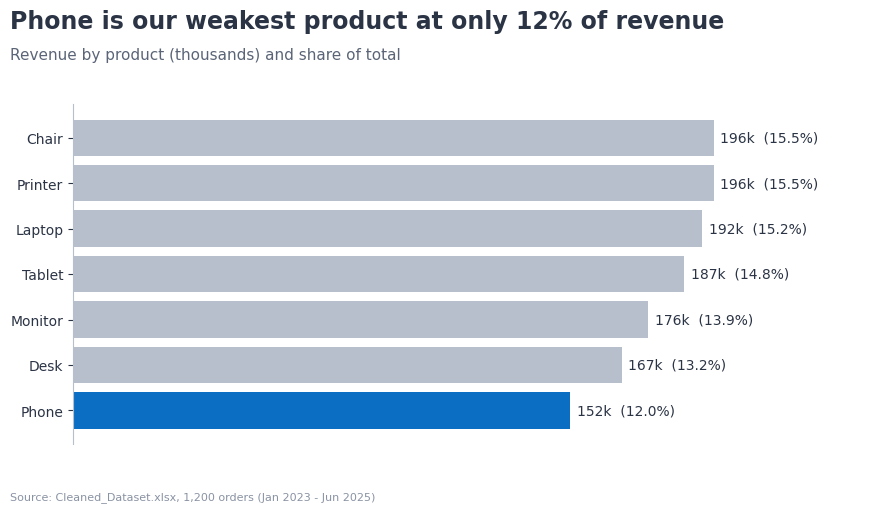

In [7]:
# SECTION 6: CHART 3 - CATEGORY COMPARISON (horizontal bar, spotlight on the weakest)
p = df.groupby("Product").TotalPrice.sum().sort_values()
colors = [ACCENT if prod == p.idxmin() else GREY for prod in p.index]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(p.index, p.values/1e3, color=colors)
for bar in bars:
    v = bar.get_width()
    ax.text(v + 2, bar.get_y() + bar.get_height()/2,
            f"{v:.0f}k  ({v*1e3/total_rev*100:.1f}%)", va="center", fontsize=10, color=DARK)
ax.set_xlim(0, p.max()/1e3 * 1.25)
ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
finish(fig, "Phone is our weakest product at only 12% of revenue",
       "Revenue by product (thousands) and share of total", "03_product_revenue")

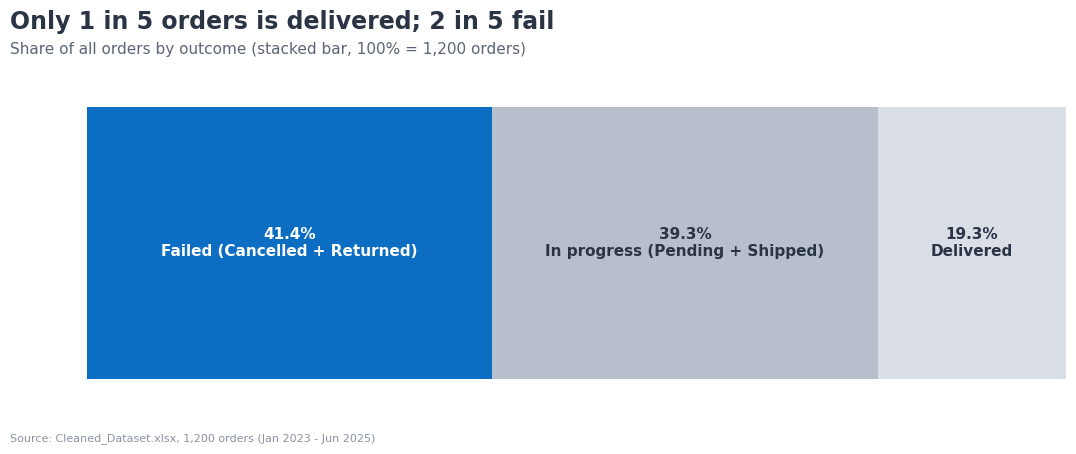

In [8]:
# SECTION 7: CHART 4 - PART OF A WHOLE (stacked bar instead of pie)
s = df.OrderStatus.value_counts(normalize=True) * 100
groups = {"Failed (Cancelled + Returned)": s[["Cancelled", "Returned"]].sum(),
          "In progress (Pending + Shipped)": s[["Pending", "Shipped"]].sum(),
          "Delivered": s["Delivered"]
          }

fig, ax = plt.subplots(figsize=(11, 4.4))
left = 0
for (label, v), color, txt in zip(groups.items(), [ACCENT, GREY, "#D9DEE7"], ["white", DARK, DARK]):
    ax.barh([0], [v], left=left, color=color, height=0.5)
    ax.text(left + v/2, 0, f"{v+1e-9:.1f}%\n{label}", ha="center", va="center",
            fontsize=11, fontweight="bold", color=txt)
    left += v
ax.set_xlim(0, 100); ax.axis("off")
finish(fig, "Only 1 in 5 orders is delivered; 2 in 5 fail",
       "Share of all orders by outcome (stacked bar, 100% = 1,200 orders)", "04_order_outcomes")

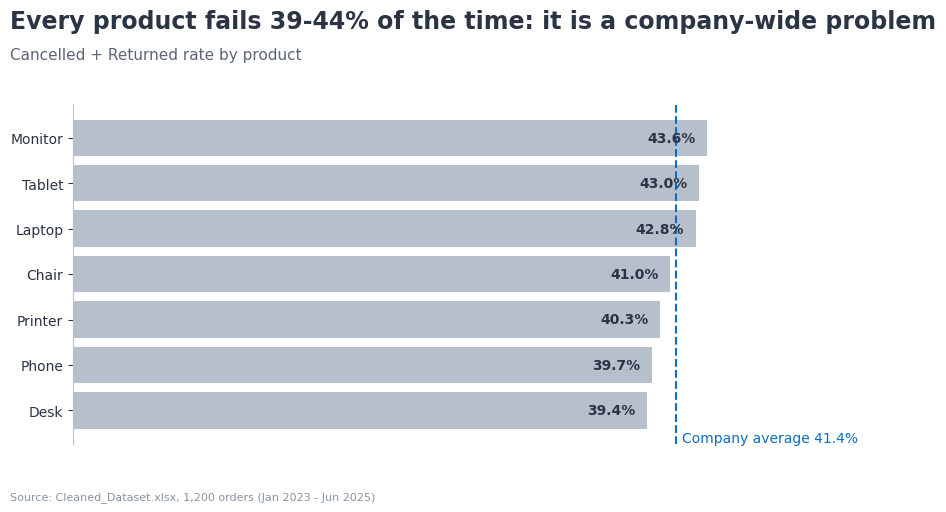

In [9]:
# SECTION 8: CHART 5 - BENCHMARK LINE (shows the problem is company-wide)
fr = (failed.groupby(df.Product).mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(fr.index, fr.values, color=GREY)
for bar in bars:
    ax.text(bar.get_width() - 0.8, bar.get_y() + bar.get_height()/2,
            f"{bar.get_width()+1e-9:.1f}%", va="center", ha="right",
            fontsize=10, fontweight="bold", color=DARK)       # label inside the bar
ax.axvline(fail_pct, color=ACCENT, ls="--")                   # company average
ax.text(fail_pct + 0.4, -0.7, f"Company average {fail_pct:.1f}%", color=ACCENT, fontsize=10)
ax.set_xlim(0, 55); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
finish(fig, "Every product fails 39-44% of the time: it is a company-wide problem",
       "Cancelled + Returned rate by product", "05_failure_by_product")